# Домашняя работа 1. Популярность и персонализация в рекомендациях

**Автор:** Скрябин Марк

**Данные:** MovieLens 1M

Цель — проверить пользу личного жанрового профиля относительно общей популярности
и baseline predictors, а также сравнить результаты для пользователей с разной популярностью истории.


## 1. Краткий разбор статей

**Результат первой статьи.** Abdollahpouri et al. (2019) на MovieLens 1M показали, что исследованные алгоритмы, кроме Random, увеличивают долю популярных фильмов в рекомендациях по сравнению с историей пользователей. Особенно заметно несоответствие для нишевой группы — 20% пользователей с наименьшей долей популярных фильмов в профиле. Это группа, выделенная по правилу, а не случайная подвыборка.

**Ограничение.** Эксперименты проведены на одном наборе данных. Переносимость величины смещения и различий между группами на другие платформы, домены и алгоритмы требует проверки. Кроме того, соответствие популярности рекомендаций истории отражает лишь одну сторону качества и не доказывает удовлетворённость пользователя.

**Что оказалось другим во второй статье.** GAP измеряет среднюю популярность объектов, а относительное изменение определяется как

$$\Delta GAP = \frac{GAP_{recommendations}-GAP_{profile}}{GAP_{profile}}.$$

В первой статье нишевая группа имела наибольшее значение $\Delta GAP$ для всех исследованных алгоритмов. У Random значение отрицательное, поэтому наибольшее значение не обязательно означает положительное смещение к популярным объектам. Kowald et al. (2020) на Last.fm не обнаружили чёткого различия между группами по $\Delta GAP$ для большинства методов; исключением был MostPopular. Авторы предполагают связь с гораздо большим каталогом: около 353 тысяч исполнителей против примерно 3900 фильмов. При этом у LowMS ошибка предсказания MAE была наибольшей для всех четырёх исследованных персонализированных методов.

**Идея для работы.** Оценивать пользу профиля отдельно для пользователей с разным интересом к популярным объектам. Сравнить собственный профиль с чужим, MostPopular и BP*, затем проверить, как польза профиля зависит от количества фильмов, использованных при его построении. Учитывать длину истории и количество положительных тестовых объектов как возможные альтернативные объяснения.

Источники: [Abdollahpouri et al., 2019](articles/origs/article_1.pdf), [Kowald et al., 2020](articles/origs/article_2.pdf).


## 2. Гипотезы до экспериментов

### Гипотеза 1: соответствие профиля владельцу полезно

- **Ожидание:** HitRate@10 у FeaturesCosineSimilarity с собственным профилем выше среднего HitRate@10 пяти запусков с чужими профилями.
- **Причина:** жанры понравившихся фильмов содержат информацию о личных предпочтениях.
- **Что меняем:** только владельца используемого жанрового профиля; каталог, пользователи, их train-запреты и test-ответы сохраняются.
- **Что сравниваем:** собственный профиль, чужой профиль, MostPopular и BP*. Coverage@10 анализируем отдельно от качества попаданий.
- **Когда пересмотрим:** если собственный профиль не превосходит чужой или преимущество неустойчиво относительно пяти подмен. Превосходство над чужим профилем само по себе не доказывает превосходство над MostPopular или BP*.

### Гипотеза 2: больше положительных примеров улучшает профиль

- **Ожидание:** средний HitRate@10 профиля по пяти фильмам выше, чем по одному; вариант по трём фильмам помогает оценить направление изменения.
- **Причина:** несколько понравившихся фильмов могут полнее описать жанровые предпочтения и уменьшить влияние случайного выбора одного фильма.
- **Что меняем:** число фильмов в профиле — 1, 3, 5. Используем вложенные случайные подмножества положительной train-истории.
- **Что сравниваем:** одних и тех же пользователей, имеющих хотя бы пять положительных train-фильмов; для всех вариантов исключаем всю исходную train-историю и сохраняем те же test-ответы.
- **Когда пересмотрим:** если пять фильмов не дают улучшения относительно одного либо эффект зависит от случайного состава профиля. Для устойчивости повторим выбор пять раз с фиксированными seeds.

Групповой анализ покажет, одинаково ли полезен профиль при разной популярности истории. Возможное альтернативное объяснение дополнительного эксперимента: изменение усреднения жанров, а не только более точное описание вкусов.


## 3. Протокол и настройки

1. Положительная оценка — **рейтинг ≥ 4** (наше допущение). BP обучаются на исходных оценках 1–5.
2. Для каждого пользователя перемешиваем исходные записи генератором NumPy PCG64 с seed 2026.
   Train содержит `floor(0.8*n)`, validation — `floor(0.1*n)`, test — остаток. Разбиение сохраняется.
3. Каталог, популярность и профили строятся только по train. Популярность — число пользователей,
   оценивших фильм, независимо от рейтинга. Каталог упорядочен по movie_id.
4. В общей оценке участвуют все пользователи; при отсутствии положительных ответов hit=0.
   Validation использует то же правило. Состав участников не подбирается по test.
5. Из рекомендаций исключаем только train-фильмы владельца выдачи. Равные scores разрешаем по movie_id.
   Для пустого положительного train-профиля score=0 для всех фильмов. В групповом анализе такие
   пользователи исключаются, поскольку средняя популярность их истории не определена.
6. Параметры выбираем по HitRate@10 на validation. При равенстве — первый параметр в указанном ниже
   порядке; для BP* порядок BP-R, BP-F, BP-N, BP-Z. Test оценивается после фиксации параметров.
7. Random и чужие профили: пять запусков, среднее и выборочное стандартное отклонение (`ddof=1`).
   Разброс запусков не является доверительным интервалом. Дополнительный эксперимент также имеет пять повторов.

Зависимости: Python ≥3.10, numpy, pandas, scipy, matplotlib, IPython.

In [1]:
import time

import numpy as np
import pandas as pd
from scipy import sparse
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 2026
POSITIVE_THRESHOLD = 4
K = 10
RANDOM_SEEDS = (201, 202, 203, 204, 205)  # Для списка фильмов у модели Random
PROFILE_SWAP_SEEDS = (201, 202, 203, 204, 205)  # Перемешивание профилей между пользователями
PROFILE_SIZE_SEEDS = (301, 302, 303, 304, 305)  # Выбор фильмов для короткого профиля

# Гиперпараметры для настройки моделей
BP_R_C = (1, 10, 100)
BP_F_C = (100, 10_000, 1_000_000)
BP_N_ALPHA = (0.01, 0.1, 1.0)

plt.rcParams.update({
    'figure.dpi': 110,
    'font.size': 10,
    'axes.grid': True,
    'grid.alpha': 0.2,
})
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda value: f'{value:.6f}')


## 4. Данные


In [2]:
ratings = pd.read_csv('data/ratings.dat', sep='::', engine='python',
                      names=['user_id', 'movie_id', 'rating', 'timestamp'],
                      dtype={'user_id': 'int32', 'movie_id': 'int32', 'rating': 'int8', 'timestamp': 'int64'})
movies = pd.read_csv('data/movies.dat', sep='::', engine='python',
                     names=['movie_id', 'title', 'genres'], encoding='latin-1')
# Индекс исходной строки позволяет сохранить и восстановить разбиение.
ratings.insert(0, 'row_id', np.arange(len(ratings)))

In [3]:
# перемешиваем оценки каждого пользователя: 80% / 10% / остаток.
split = np.empty(len(ratings), dtype=np.uint8)

rng = np.random.default_rng(SEED)
for idx in ratings.groupby('user_id', sort=True).indices.values():
    shuffled = rng.permutation(idx)
    n_train, n_val = int(0.8 * len(idx)), int(0.1 * len(idx))
    split[shuffled[:n_train]] = 0
    split[shuffled[n_train:n_train + n_val]] = 1
    split[shuffled[n_train + n_val:]] = 2

ratings['split'] = pd.Categorical.from_codes(split, ['train', 'validation', 'test'])
train = ratings.loc[split == 0].copy()
validation = ratings.loc[split == 1].copy()
test = ratings.loc[split == 2].copy()
np.savez_compressed('data/split_seed2026.npz', row_id=ratings.row_id.to_numpy(), split=split)

In [4]:
# Внешние ID переводим во внутренние индексы строк/столбцов матриц.
user_ids = np.sort(ratings.user_id.unique())
movie_ids = np.sort(train.movie_id.unique())
num_users, num_movies = len(user_ids), len(movie_ids)
train_user_indices = np.searchsorted(user_ids, train.user_id.to_numpy()).astype(np.int32)
train_movie_indices = np.searchsorted(movie_ids, train.movie_id.to_numpy()).astype(np.int32)
train_ratings = train.rating.to_numpy(dtype=float)
# Единица означает наличие train-оценки, независимо от её величины.
train_interactions = sparse.csr_matrix((np.ones(len(train)), (train_user_indices, train_movie_indices)), shape=(num_users, num_movies))
user_rating_counts = np.asarray(train_interactions.sum(axis=1)).ravel()
movie_popularity = np.asarray(train_interactions.sum(axis=0)).ravel()
mu = train_ratings.mean()

In [5]:
def positive_matrix(frame):
    """Преобразовать оценки >=4 в матрицу положительных ответов.

    frame — train, validation или test с исходными user_id/movie_id.
    Возвращается CSR-матрица (num_users, num_movies): 1 для положительной пары,
    0 для остальных. Фильмы вне train-каталога не попадают в матрицу.
    """
    positive_ratings = frame.loc[(frame.rating >= POSITIVE_THRESHOLD) & frame.movie_id.isin(movie_ids)]
    user_index = np.searchsorted(user_ids, positive_ratings.user_id.to_numpy())
    movie_index = np.searchsorted(movie_ids, positive_ratings.movie_id.to_numpy())
    return sparse.csr_matrix((np.ones(len(positive_ratings), dtype=np.int8), (user_index, movie_index)), shape=(num_users, num_movies))

positive_train = positive_matrix(train)
truth_val, truth_test = positive_matrix(validation), positive_matrix(test)
positive_count = positive_train.getnnz(axis=1)
summary_rows = []
for name, frame, positive_answers in [
    ('train', train, positive_train),
    ('validation', validation, truth_val),
    ('test', test, truth_test),
]:
    summary_rows.append({
        'part': name,
        'ratings': len(frame),
        'users': frame.user_id.nunique(),
        'positive_in_catalog': int(positive_answers.nnz),
        'users_without_positive_in_catalog': int((positive_answers.getnnz(axis=1) == 0).sum()),
        'ratings_outside_catalog': int((~frame.movie_id.isin(movie_ids)).sum()),
    })
summary = pd.DataFrame(summary_rows)
display(summary)
print(f'Всего пользователей и участников общей оценки: {num_users}; каталог: {num_movies}; фильмов в metadata: {len(movies)}')
print(f'Пустых положительных train-историй: {(positive_count == 0).sum()}; средняя оценка train: {mu:.6f}')


,part,ratings,users,positive_in_catalog,users_without_positive_in_catalog,ratings_outside_catalog
0,train,797758,6040,458730,3,0
1,validation,97383,6040,55867,171,10
2,test,105068,6040,60680,104,17


Всего пользователей и участников общей оценки: 6040; каталог: 3682; фильмов в metadata: 3883
Пустых положительных train-историй: 3; средняя оценка train: 3.581581


## 5. Теоретическое задание

При одном наборе кандидатов и одном правиле разрешения равенств для BP

$$s_{ui}-s_{uj}=(\mu+g_u+f_i)-(\mu+g_u+f_j)=f_i-f_j.$$

Разность не зависит от пользователя. Следовательно, относительный порядок общий.

Для линейной регрессии разделим веса на части, соответствующие пользователю и фильму:

$$s_{ui}=b+\theta_x^T x_u+\theta_z^T z_i, \qquad
s_{ui}-s_{uj}=\theta_z^T(z_i-z_j).$$

Разность вновь не зависит от пользователя. Конкатенация признаков без взаимодействий не создаёт
персонализированный порядок. Разные top-10 BP после исключения train-истории могут возникать
из-за разных доступных наборов. Пользовательский сдвиг оценок сам по себе порядок не меняет.


## 6. Общие функции рекомендаций и метрик

Top-10 (top-k) выбирается по пороговому score с явной обработкой равенств по movie_id

In [ ]:
def topk_rows(scores, k=K):
    """Выбрать k лучших фильмов для каждой строки матрицы scores.

    Вход: scores размера (число пользователей, размер каталога).
    Запрещённым фильмам заранее присваивается -inf.
    Выход: матрица индексов фильмов размера (число пользователей, k).
    Столбцы scores соответствуют возрастающим movie_id, поэтому меньший индекс
    разрешает равенство scores в пользу меньшего movie_id.
    """
    scores = np.asarray(scores)
    recommendations = np.empty((len(scores), k), dtype=np.int32)

    for row_index, row_scores in enumerate(scores):
        # Находим score на границе top-k без полной сортировки каталога.
        cutoff = np.partition(row_scores, -k)[-k]
        better_indices = np.flatnonzero(row_scores > cutoff)

        # При равенстве порогу добираем фильмы с меньшими movie_id.
        remaining_slots = k - len(better_indices)
        tied_indices = np.flatnonzero(row_scores == cutoff)[:remaining_slots]
        candidates = np.concatenate([better_indices, tied_indices])

        # lexsort использует последний ключ первым: сначала -score, затем индекс.
        order = np.lexsort((candidates, -row_scores[candidates]))
        recommendations[row_index] = candidates[order]

    return recommendations


def recommend(score_function, users=None, batch_size=128):
    """Сформировать top-10, исключив train-фильмы владельца каждой выдачи.

    score_function получает массив внутренних индексов пользователей и возвращает
    scores всех фильмов каталога. users=None означает всех пользователей.
    Возвращается матрица внутренних индексов фильмов в порядке массива users.
    Пакеты по batch_size строк позволяют не хранить полную плотную матрицу scores.
    """
    if users is None:
        users = np.arange(num_users)
    else:
        users = np.asarray(users)

    recommendation_batches = []
    for start in range(0, len(users), batch_size):
        batch_users = users[start:start + batch_size]
        scores = np.array(score_function(batch_users), dtype=float, copy=True)

        # Координаты известных train-пар внутри текущего пакета.
        seen_movies = train_interactions[batch_users].tocoo()
        scores[seen_movies.row, seen_movies.col] = -np.inf
        recommendation_batches.append(topk_rows(scores))

    return np.vstack(recommendation_batches)


def recommend_by_movie_scores(movie_scores, users=None):
    """Получить рекомендации по одному общему вектору scores фильмов.

    Подходит для MostPopular и всех BP: их относительный порядок не зависит
    от пользователя, а разные train-запреты применяет функция recommend.
    """
    def score_batch(batch_users):
        """Повторить общий вектор scores для пользователей текущего пакета."""
        return np.broadcast_to(movie_scores, (len(batch_users), num_movies))

    return recommend(score_batch, users=users)


def recommend_by_profiles(user_profiles, users=None):
    """Получить рекомендации по нормированным жанровым профилям пользователей.

    user_profiles имеет форму (num_users, число жанров), включая строки,
    не участвующие в оценке. Скалярное произведение нормированных векторов
    профиля и фильма равно косинусному сходству.
    """
    def score_batch(batch_users):
        """Вычислить косинусное сходство профилей пакета со всеми фильмами."""
        return user_profiles[batch_users] @ genre_vectors.T

    return recommend(score_batch, users=users)


def metrics(recommendations, positive_answers, users=None, n_items=None):
    """Посчитать HitRate@10, Coverage@10 и индикаторы попадания пользователей.

    recommendations — внутренние индексы фильмов, строки соответствуют users.
    positive_answers — разреженная матрица положительных validation/test-ответов
    всех пользователей. users=None означает пользователей 0..число строк-1.
    n_items — размер каталога; обычно num_movies, в учебном примере — 4.
    Возвращает пару: словарь двух общих метрик и массив нулей/единиц по людям.
    """
    if users is None:
        users = np.arange(len(recommendations))
    else:
        users = np.asarray(users)
    if n_items is None:
        n_items = num_movies

    # Берём ответы только для рекомендованных фильмов: по 10 значений на человека.
    relevant_answers = positive_answers[users[:, None], recommendations]
    if sparse.issparse(relevant_answers):
        relevant_answers = relevant_answers.toarray()
    else:
        relevant_answers = np.asarray(relevant_answers)

    hits = (relevant_answers > 0).any(axis=1).astype(np.int8)
    hit_rate = float(hits.mean())
    coverage = len(np.unique(recommendations)) / n_items
    return {'HitRate@10': hit_rate, 'Coverage@10': coverage}, hits

## 7. Жанровая модель и простые baselines

Нормируем каждый бинарный вектор жанров до единичной длины. Профиль — среднее этих
векторов по положительной train-истории; для косинуса нормируем также профиль.
Random выбирает десять разных доступных фильмов равномерно без возвращения.


In [7]:
# Строки каталога идут по movie_id: тот же порядок используется в scores.
catalog_movies = movies.set_index('movie_id').loc[movie_ids]
genres = sorted({genre for text in catalog_movies.genres for genre in text.split('|')})
genre_vectors = np.array([
    [genre in text.split('|') for genre in genres]
    for text in catalog_movies.genres
], dtype=float)

# Каждый фильм может иметь несколько жанров. Нормируем его вектор до длины 1.
movie_vector_lengths = np.linalg.norm(genre_vectors, axis=1, keepdims=True)
genre_vectors /= np.maximum(movie_vector_lengths, 1e-15)


def normalize_profiles(profile_vectors):
    """Нормировать строки матрицы профилей до единичной длины.

    Вход и выход имеют форму (число пользователей, число жанров).
    Нулевые профили остаются нулевыми: нижняя граница знаменателя защищает
    от деления на ноль и даёт им нулевой cosine score для всех фильмов.
    """
    lengths = np.linalg.norm(profile_vectors, axis=1, keepdims=True)
    return profile_vectors / np.maximum(lengths, 1e-15)


# Разреженное умножение суммирует жанровые векторы положительных train-фильмов.
profile_sums = np.asarray(positive_train @ genre_vectors)
profiles = profile_sums / np.maximum(positive_count[:, None], 1)
normalized_profiles = normalize_profiles(profiles)

own_recs = recommend_by_profiles(normalized_profiles)
popular_recs = recommend_by_movie_scores(movie_popularity)


def random_recommendations(seed):
    """Равномерно выбрать 10 разных доступных фильмов каждому пользователю.

    seed фиксирует случайность. Train-фильмы исключаются до выбора.
    Выход: матрица внутренних индексов (num_users, K).
    """
    rng = np.random.default_rng(seed)
    all_movie_indices = np.arange(num_movies)
    recommendations = np.empty((num_users, K), dtype=np.int32)

    for user_index in range(num_users):
        start = train_interactions.indptr[user_index]
        stop = train_interactions.indptr[user_index + 1]
        seen_indices = train_interactions.indices[start:stop]
        available_indices = np.setdiff1d(all_movie_indices, seen_indices, assume_unique=True)
        recommendations[user_index] = rng.choice(available_indices, K, replace=False)

    return recommendations


print(f'Жанров: {len(genres)}. MostPopular и собственный профиль используют только train.')


Жанров: 18. MostPopular и собственный профиль используют только train.


## 8. Обучение BP: целевые функции и оптимизация

Для BP-R и BP-F минимизируем

$$\sum_{(u,i)\in O}(r_{ui}-\mu-g_u-f_i)^2+
\sum_u\gamma_u g_u^2+\sum_i\lambda_i f_i^2.$$

В BP-R $\gamma_u=\lambda_i=c$, в BP-F $\gamma_u=c/q(u)$, $\lambda_i=c/p(i)$.
Для BP-N к этой сумме ошибок на O добавляется $\alpha\sum_{(u,i)\in N}(\mu+g_u+f_i)^2$,
а регуляризация отсутствует. N — мультимножество, повторы имеют кратный вес.

Используем точную минимизацию по всем g при фиксированных f и наоборот. Если W содержит
суммарные веса пар, D — суммы весов плюс регуляризация, а b — взвешенные суммы $(r-\mu)$,
то обновления: $g=(b_u-Wf)/D_u$, $f=(b_i-W^Tg)/D_i$.
Это выпуклая квадратичная задача. Между шагами выбираем оптимальный общий сдвиг g/f,
не меняющий предсказания. Для BP-N фиксируем среднее g=0 (неидентифицируемость разложения).
Критерий остановки: максимум нормированных остатков нормальных уравнений < $10^{-9}$.
История целевой функции остаётся в словаре модели для анализа сходимости.


In [8]:
# Один и тот же набор N для всех alpha. Сохраняем каждое вхождение и явные нулевые targets.
negative_rng = np.random.default_rng(SEED)
negative_user_indices = np.repeat(np.arange(num_users, dtype=np.int32), (10*user_rating_counts).astype(int))
negative_movie_indices = np.empty(len(negative_user_indices), dtype=np.int32)
offset, all_items = 0, np.arange(num_movies, dtype=np.int32)

# Выбираем 10 нулевых примеров на каждую исходную train-оценку.
for user_index in range(num_users):
    available = np.setdiff1d(all_items, train_interactions.indices[train_interactions.indptr[user_index]:train_interactions.indptr[user_index+1]], assume_unique=True)
    count = int(10*user_rating_counts[user_index])
    negative_movie_indices[offset:offset+count] = negative_rng.choice(available, count, replace=True)
    offset += count
np.savez_compressed('data/negative_examples_seed2026.npz',
                    user_index=negative_user_indices, movie_index=negative_movie_indices, target=np.zeros(len(negative_user_indices), dtype=np.int8),
                    user_id_mapping=user_ids, movie_id_mapping=movie_ids)
negative_pair_counts = sparse.csr_matrix((np.ones(len(negative_user_indices)), (negative_user_indices, negative_movie_indices)), shape=(num_users, num_movies))
print(f'N: {len(negative_user_indices):,} примеров, {negative_pair_counts.nnz:,} разных пар; повторы сохранены.')
del negative_user_indices, negative_movie_indices

user_rating_sums = np.bincount(train_user_indices, weights=train_ratings, minlength=num_users)
movie_rating_sums = np.bincount(train_movie_indices, weights=train_ratings, minlength=num_movies)


N: 7,977,580 примеров, 5,495,529 разных пар; повторы сохранены.


In [9]:
def fit_bp(family, parameter, tol=1e-9, max_iter=2000):
    """Обучить BP-R, BP-F или BP-N чередующимися точными обновлениями.

    family — название семейства; parameter — c для BP-R/BP-F или alpha для BP-N.
    mu фиксировано и равно среднему исходных train-рейтингов.
    На каждом шаге минимизируем loss по поправкам пользователей при фиксированных
    поправках фильмов, затем наоборот. tol — допустимый остаток нормальных
    уравнений, max_iter — ограничение числа шагов.

    Возвращает словарь: g (поправки пользователей), f (поправки фильмов),
    параметр, число шагов, остаток, loss, RMSE исходных train-пар и историю.
    Ключи g/f соответствуют обозначениям в теоретической части.
    """
    # Веса регуляризации и пар задают различия между тремя постановками.
    if family == 'BP-R':
        user_penalties = np.full(num_users, parameter)
        movie_penalties = np.full(num_movies, parameter)
        pair_weights = train_interactions
    elif family == 'BP-F':
        user_penalties = parameter / user_rating_counts
        movie_penalties = parameter / movie_popularity
        pair_weights = train_interactions
    elif family == 'BP-N':
        user_penalties = np.zeros(num_users)
        movie_penalties = np.zeros(num_movies)
        pair_weights = train_interactions + parameter * negative_pair_counts
    else:
        raise ValueError(f'Неизвестное семейство BP: {family}')

    user_weight_sums = np.asarray(pair_weights.sum(axis=1)).ravel()
    movie_weight_sums = np.asarray(pair_weights.sum(axis=0)).ravel()
    user_denominators = user_weight_sums + user_penalties
    movie_denominators = movie_weight_sums + movie_penalties

    # Искусственные нули не добавляют рейтинги к суммам, но добавляют вес к -mu.
    user_targets = user_rating_sums - mu * user_weight_sums
    movie_targets = movie_rating_sums - mu * movie_weight_sums
    constant_loss = np.sum((train_ratings - mu) ** 2)
    if family == 'BP-N':
        constant_loss += parameter * negative_pair_counts.sum() * mu ** 2

    user_biases = np.zeros(num_users)
    movie_biases = np.zeros(num_movies)
    transposed_weights = pair_weights.T.tocsr()
    history = []

    for iteration in range(1, max_iter + 1):
        # Точные минимумы квадратичной функции по каждой из двух групп параметров.
        user_biases = (user_targets - pair_weights @ movie_biases) / user_denominators
        movie_biases = (movie_targets - transposed_weights @ user_biases) / movie_denominators

        # Сдвиг g+=shift, f-=shift сохраняет все суммы g_u+f_i.
        if family == 'BP-N':
            shift = -user_biases.mean()
        else:
            shift = (
                movie_penalties @ movie_biases - user_penalties @ user_biases
            ) / (user_penalties.sum() + movie_penalties.sum())
        user_biases += shift
        movie_biases -= shift

        # Остаток показывает, насколько текущие параметры далеки от стационарной точки.
        user_residual = user_biases + (
            pair_weights @ movie_biases - user_targets
        ) / user_denominators
        movie_residual = movie_biases + (
            transposed_weights @ user_biases - movie_targets
        ) / movie_denominators
        residual = max(np.max(np.abs(user_residual)), np.max(np.abs(movie_residual)))

        # Разложенная квадратичная форма: loss без построения полной матрицы scores.
        loss = float(
            constant_loss
            - 2 * user_targets @ user_biases
            - 2 * movie_targets @ movie_biases
            + user_denominators @ (user_biases * user_biases)
            + movie_denominators @ (movie_biases * movie_biases)
            + 2 * user_biases @ (pair_weights @ movie_biases)
        )
        history.append((iteration, loss, residual))
        if residual < tol:
            break

    if residual >= tol:
        raise RuntimeError(f'{family}: не достигнута сходимость за {max_iter} шагов')

    predicted_train_ratings = mu + user_biases[train_user_indices] + movie_biases[train_movie_indices]
    train_rmse = np.sqrt(np.mean((train_ratings - predicted_train_ratings) ** 2))
    return {
        'family': family,
        'parameter': parameter,
        'g': user_biases,
        'f': movie_biases,
        'iterations': iteration,
        'residual': residual,
        'loss': loss,
        'train_rmse': float(train_rmse),
        'history': history,
    }


In [10]:
all_models, val_rows = {}, []
for family, grid in [('BP-R', BP_R_C), ('BP-F', BP_F_C), ('BP-N', BP_N_ALPHA)]:
    for parameter in grid:
        started = time.perf_counter()
        model = fit_bp(family, parameter)
        recs = recommend_by_movie_scores(model['f'])
        result, _ = metrics(recs, truth_val)
        all_models[(family, parameter)] = model
        val_rows.append({'model': family, 'parameter': parameter, **result,
                         'iterations': model['iterations'], 'residual': model['residual'],
                         'train_rmse': model['train_rmse']})
        print(f'{family}, parameter={parameter}: HR_val={result["HitRate@10"]:.6f}, '
              f'iterations={model["iterations"]}, time={time.perf_counter()-started:.1f}s', flush=True)


BP-R, parameter=1: HR_val=0.061589, iterations=16, time=5.5s


BP-R, parameter=10: HR_val=0.197351, iterations=15, time=3.0s


BP-R, parameter=100: HR_val=0.281788, iterations=10, time=3.1s


BP-F, parameter=100: HR_val=0.182616, iterations=34, time=3.1s


BP-F, parameter=10000: HR_val=0.247351, iterations=32, time=2.7s


BP-F, parameter=1000000: HR_val=0.410099, iterations=6, time=3.8s


BP-N, parameter=0.01: HR_val=0.293874, iterations=14, time=5.3s


BP-N, parameter=0.1: HR_val=0.412583, iterations=8, time=4.2s


BP-N, parameter=1.0: HR_val=0.423013, iterations=6, time=4.3s


In [11]:
# BP-Z: строка + столбец - среднее по полной матрице с нулями.
a, b, m = user_rating_sums/num_movies, movie_rating_sums/num_users, train_ratings.sum()/(num_users*num_movies)
z_recs = recommend_by_movie_scores(b)
z_result, _ = metrics(z_recs, truth_val)
all_models[('BP-Z', None)] = {'family': 'BP-Z', 'parameter': None, 'g': a, 'f': b,
                             'iterations': 0, 'residual': 0., 'loss': np.nan,
                             'train_rmse': float(np.sqrt(np.mean((train_ratings-a[train_user_indices]-b[train_movie_indices]+m)**2)))}
val_rows.append({'model': 'BP-Z', 'parameter': np.nan, **z_result, 'iterations': 0,
                 'residual': 0., 'train_rmse': all_models[('BP-Z', None)]['train_rmse']})
validation_results = pd.DataFrame(val_rows)


In [12]:
# idxmax возвращает первую строку при равенстве
selected = {}
selected_row_indices = []
for family in ['BP-R', 'BP-F', 'BP-N', 'BP-Z']:
    family_results = validation_results.loc[validation_results.model == family]
    best_row_index = family_results['HitRate@10'].idxmax()
    selected_row_indices.append(best_row_index)
    best_parameter = validation_results.loc[best_row_index, 'parameter']
    if family == 'BP-Z':
        best_parameter = None
    selected[family] = all_models[(family, best_parameter)]

selected_validation = validation_results.loc[selected_row_indices].copy()
best_bp_row = selected_validation['HitRate@10'].idxmax()
best_bp = selected_validation.loc[best_bp_row, 'model']
display(validation_results)
display(selected_validation)
print('Зафиксирован BP*:', best_bp)


,model,parameter,HitRate@10,Coverage@10,iterations,residual,train_rmse
0,BP-R,1.000000,0.061589,0.005975,16,0.000000,0.896080
1,BP-R,10.000000,0.197351,0.010864,15,0.000000,0.898232
2,BP-R,100.000000,0.281788,0.013036,10,0.000000,0.926315
3,BP-F,100.000000,0.182616,0.010320,34,0.000000,0.896883
4,BP-F,10000.000000,0.247351,0.012222,32,0.000000,0.924202
5,BP-F,1000000.000000,0.410099,0.017653,6,0.000000,1.052407
6,BP-N,0.010000,0.293874,0.013851,14,0.000000,0.973853
7,BP-N,0.100000,0.412583,0.017925,8,0.000000,1.583494
8,BP-N,1.000000,0.423013,0.018740,6,0.000000,2.868060
9,BP-Z,NaN,0.425000,0.018197,0,0.000000,3.199384


,model,parameter,HitRate@10,Coverage@10,iterations,residual,train_rmse
2,BP-R,100.000000,0.281788,0.013036,10,0.000000,0.926315
5,BP-F,1000000.000000,0.410099,0.017653,6,0.000000,1.052407
8,BP-N,1.000000,0.423013,0.018740,6,0.000000,2.868060
9,BP-Z,NaN,0.425000,0.018197,0,0.000000,3.199384


Зафиксирован BP*: BP-Z


## 9. Поправки фильмов и удаление пользовательского сдвига

Для BP-Z используем параметризацию $f_i=b(i)$: общий сдвиг не влияет на порядок.
Популярность по горизонтали показана в логарифмическом масштабе. Корреляция Спирмена описывает
монотонную связь; она не устанавливает причину. Многожанровый фильм входит в обе жанровые выборки.


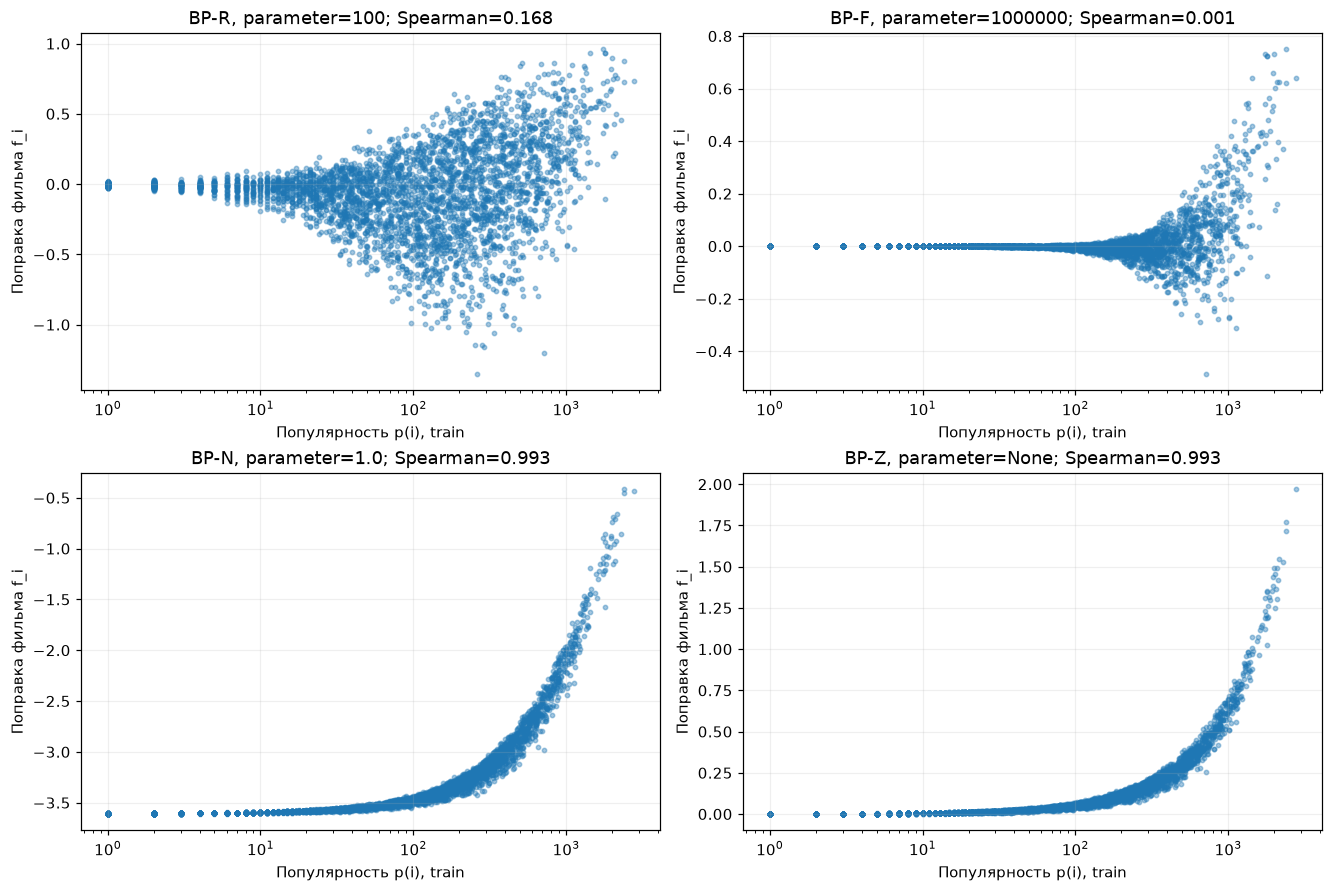

,model,parameter,spearman_p_f
0,BP-R,100.000000,0.167838
1,BP-F,1000000.000000,0.001401
2,BP-N,1.000000,0.993413
3,BP-Z,NaN,0.993309


,genre,n,mean,median,std
0,Horror,337,-0.241311,-0.226445,0.283212
1,Drama,1477,0.044384,0.004515,0.241096


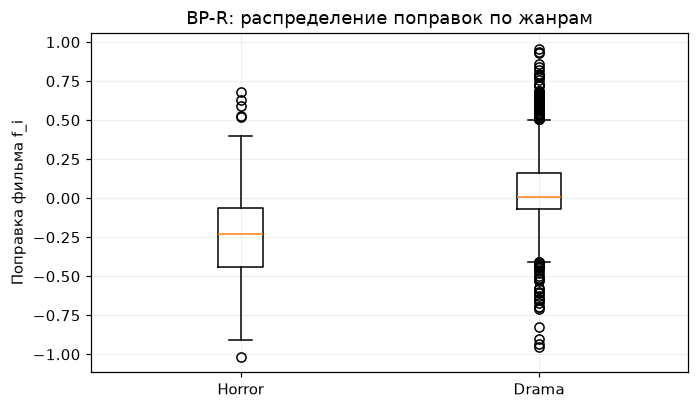

,variant,HitRate@10,Coverage@10
0,BP-R,0.306291,0.013036
1,BP-R without g_u,0.306291,0.013036


Доля полностью совпавших top-10: 100.00%


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
correlation_rows = []
for ax, (family, model) in zip(axes.flat, selected.items()):
    rho = float(spearmanr(movie_popularity, model['f']).statistic)
    correlation_rows.append({'model': family, 'parameter': model['parameter'], 'spearman_p_f': rho})
    ax.scatter(movie_popularity, model['f'], s=8, alpha=0.4, rasterized=True)
    ax.set(xscale='log', xlabel='Популярность p(i), train', ylabel='Поправка фильма f_i',
           title=f'{family}, parameter={model["parameter"]}; Spearman={rho:.3f}')
plt.show()
plt.close(fig)
correlations = pd.DataFrame(correlation_rows)
display(correlations)

genre_rows, genre_values = [], []
for genre in ['Horror', 'Drama']:
    mask = catalog_movies.genres.str.split('|').map(lambda x: genre in x).to_numpy()
    values = selected['BP-R']['f'][mask]
    genre_values.append(values)
    genre_rows.append({'genre': genre, 'n': len(values), 'mean': values.mean(),
                       'median': np.median(values), 'std': values.std(ddof=1)})
genre_stats = pd.DataFrame(genre_rows)
display(genre_stats)
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(genre_values, tick_labels=['Horror', 'Drama'], showfliers=True)
ax.set(ylabel='Поправка фильма f_i', title='BP-R: распределение поправок по жанрам')
plt.show()
plt.close(fig)

model = selected['BP-R']
def scores_with_user_bias(batch_users):
    """Посчитать полные scores выбранного BP-R: mu + g_u + f_i."""
    return mu + model['g'][batch_users, None] + model['f'][None, :]


before = recommend(scores_with_user_bias)
after = recommend_by_movie_scores(mu + model['f'])
ablation = pd.DataFrame([{'variant': name, **metrics(recs, truth_test)[0]}
                        for name, recs in [('BP-R', before), ('BP-R without g_u', after)]])
identical_fraction = float(np.all(before == after, axis=1).mean())
display(ablation)
print(f'Доля полностью совпавших top-10: {identical_fraction:.2%}')


**Интерпретация поправок.** У выбранного BP-R связь популярности и поправки имеет
Spearman **0.168**. Постоянная регуляризация сильнее ограничивает относительное влияние
поправок объектов с малым количеством оценок: в обновлении f знаменатель p(i)+c.
В BP-F штраф c/p(i) у редких фильмов больше, а у частых меньше; сравнивать только численные c
между семействами нельзя, поскольку масштабы разные. После подбора BP-F имеет Spearman
**0.001**: почти нулевая ранговая корреляция не исключает видимую на графике зависимость
масштаба разброса от популярности. У редких объектов поправки сжаты к нулю,
у частых встречаются большие значения обоих знаков.

В BP-N высокие scores штрафуются на искусственных нулевых примерах: меняется сама задача,
а не только величина регуляризации. BP-N и BP-Z имеют сильную положительную ранговую
связь с популярностью: **0.993** и **0.993** соответственно.
В BP-Z поправка пропорциональна сумме оценок, поэтому связь с их количеством ожидаема.
Средняя поправка Horror **-0.241**, Drama **0.044**:
в выбранном BP-R распределение Horror сдвинуто ниже. Это не доказывает влияние жанра
независимо от состава аудитории и популярности.

Удаление g_u без переобучения сохранило **100%** списков, HitRate и Coverage.
Это согласуется с доказательством: общий для всех фильмов пользователя сдвиг порядок не меняет.

## 10. Свои и чужие профили: итоговое сравнение на test

Генерируем случайную перестановку до отсутствия неподвижных точек.
Каждый профиль используется ровно один раз, никто не получает свой. Запреты и test-ответы
принадлежат исходному пользователю.


In [14]:
def derangement(n, seed):
    """Случайно назначить каждому пользователю чужой профиль.

    Возвращает перестановку индексов 0..n-1 без неподвижных точек.
    perm[u] — индекс донора профиля для пользователя u. Каждый донор
    используется один раз; seed делает назначение воспроизводимым (n>=2).
    """
    rng = np.random.default_rng(seed)
    while True:
        perm = rng.permutation(n)
        if np.all(perm != np.arange(n)):
            return perm


In [15]:
deterministic_recs = {'MostPopular': popular_recs, 'FeaturesOwn': own_recs}
for family, model in selected.items():
    deterministic_recs[family] = recommend_by_movie_scores(model['f'])
random_recs, swapped_recs, permutations, run_rows, hits_by_model = [], [], [], [], {}
for name, recs in deterministic_recs.items():
    met, hits_by_model[name] = metrics(recs, truth_test)
    run_rows.append({'model': name, 'seed': np.nan, **met})
for seed in RANDOM_SEEDS:
    recs = random_recommendations(seed)
    random_recs.append(recs)
    run_rows.append({'model': 'Random', 'seed': seed, **metrics(recs, truth_test)[0]})
for seed in PROFILE_SWAP_SEEDS:
    perm = derangement(num_users, seed)
    # Переставляем только профили: train-запреты остаются у владельца выдачи.
    foreign_profiles = normalized_profiles[perm]
    recs = recommend_by_profiles(foreign_profiles)
    swapped_recs.append(recs)
    permutations.append(perm)
    run_rows.append({'model': 'FeaturesForeign', 'seed': seed, **metrics(recs, truth_test)[0]})
hits_foreign = np.stack([metrics(recs, truth_test)[1] for recs in swapped_recs])
runs = pd.DataFrame(run_rows)


,parameter,runs,HitRate@10_mean,HitRate@10_std,Coverage@10_mean,Coverage@10_std
model,,,,,,
Random,-,5,0.029106,0.001823,1.000000,0.000000
MostPopular,-,1,0.453477,0.000000,0.018740,0.000000
BP-R,100,1,0.306291,0.000000,0.013036,0.000000
BP-F,1000000,1,0.434272,0.000000,0.017653,0.000000
BP-N,1.0,1,0.462583,0.000000,0.018740,0.000000
BP-Z,-,1,0.465066,0.000000,0.018197,0.000000
FeaturesOwn,-,1,0.108775,0.000000,0.315046,0.000000
FeaturesForeign,-,5,0.042914,0.001800,0.286638,0.002979


,model,seed,HitRate@10,Coverage@10
0,Random,201.000000,0.029305,1.000000
1,Random,202.000000,0.028974,1.000000
2,Random,203.000000,0.026987,1.000000
3,Random,204.000000,0.028311,1.000000
4,Random,205.000000,0.031954,1.000000
5,FeaturesForeign,201.000000,0.040894,0.282727
6,FeaturesForeign,202.000000,0.041887,0.288702
7,FeaturesForeign,203.000000,0.045695,0.287072
8,FeaturesForeign,204.000000,0.042881,0.284628
9,FeaturesForeign,205.000000,0.043212,0.290060


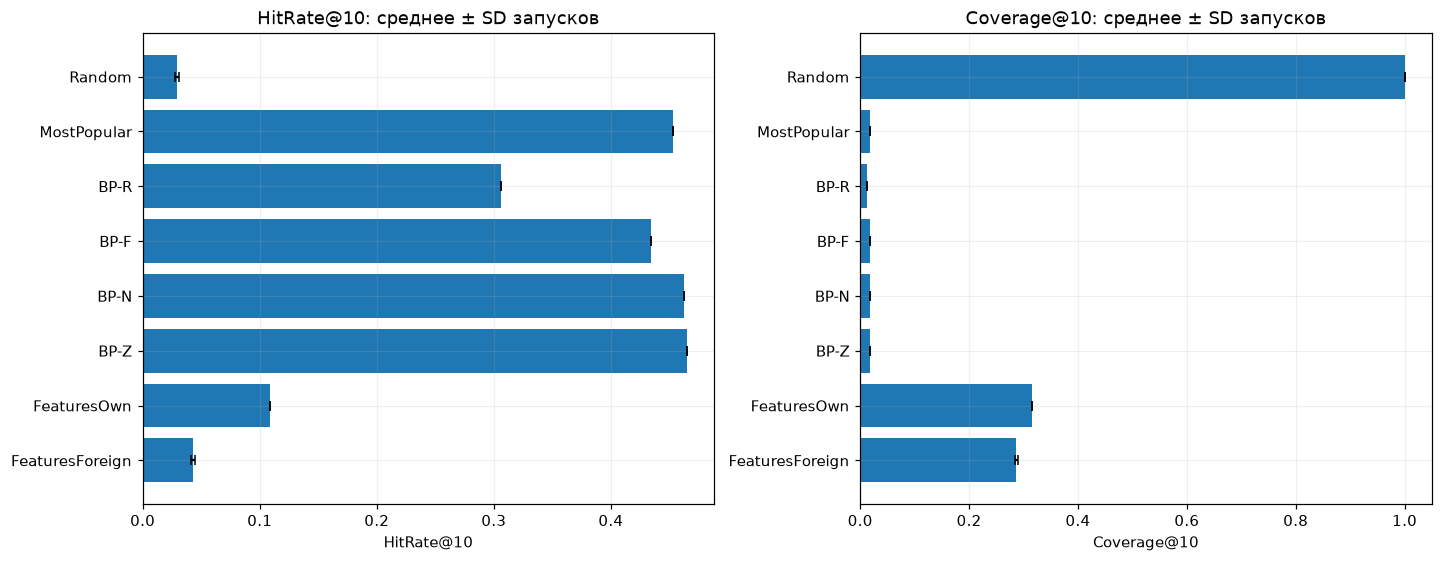

In [16]:
order = ['Random', 'MostPopular', 'BP-R', 'BP-F', 'BP-N', 'BP-Z', 'FeaturesOwn', 'FeaturesForeign']
result_rows = []
for name in order:
    model_runs = runs.loc[runs.model == name]
    parameter_text = '-'
    if name in selected and selected[name]['parameter'] is not None:
        parameter_text = str(selected[name]['parameter'])

    result_row = {'model': name, 'parameter': parameter_text, 'runs': len(model_runs)}
    for metric_name in ['HitRate@10', 'Coverage@10']:
        result_row[metric_name + '_mean'] = model_runs[metric_name].mean()
        if len(model_runs) > 1:
            result_row[metric_name + '_std'] = model_runs[metric_name].std(ddof=1)
        else:
            result_row[metric_name + '_std'] = 0.0
    result_rows.append(result_row)
results = pd.DataFrame(result_rows).set_index('model').loc[order]
display(results)
display(runs.loc[runs.seed.notna()].reset_index(drop=True))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, metric in zip(axes, ['HitRate@10', 'Coverage@10']):
    ax.barh(order, results[metric+'_mean'], xerr=results[metric+'_std'], capsize=3)
    ax.invert_yaxis()
    ax.set(xlabel=metric, title=metric + ': среднее ± SD запусков')
plt.show()
plt.close(fig)


**Проверка гипотезы 1.** HitRate собственного профиля **0.1088**,
чужого — **0.0429 ± 0.0018**; разность **+0.0659**
(+6.59 процентного пункта). Диапазон пяти чужих профилей:
[0.0409; 0.0457].
Гипотеза поддерживается по направлению среднего эффекта.
Собственный профиль превышает все пять чужих запусков.

Сравнение с MostPopular: **-0.3447**, с BP* (BP-Z): **-0.3563**.
Польза соответствия профиля владельцу и превосходство над неперсонализированным baseline —
разные утверждения. Жанры могут давать полезный личный сигнал, но не обязательно более сильный,
чем общая популярность или поправки фильмов. Пять подмен оценивают случайность назначения профилей;
они не доказывают статистическую значимость и не характеризуют неопределённость разбиения данных.

## 11. Для кого полезен профиль

Группы определяем только по train: средняя популярность положительных фильмов, сортировка
по этому среднему и user_id, затем три примерно равные части. Это отличается от нишевых 20%
в первой статье. Чужие профили берём из общих перестановок, BP* остаётся общим.


,group,users,mean_positive_train_length,mean_positive_test_in_catalog,mean_history_popularity,MostPopular_HR,BP_star_HR,Own_HR,Foreign_HR_mean,Foreign_HR_std,Own_minus_Foreign
0,Low popularity,2013,117.910581,15.281669,612.532858,0.412817,0.419771,0.123696,0.060606,0.005396,0.063090
1,Medium popularity,2012,74.758946,9.919980,831.177344,0.499503,0.512425,0.118787,0.043738,0.003353,0.075050
2,High popularity,2012,35.268887,4.949304,1099.823590,0.448807,0.463718,0.083996,0.024453,0.001548,0.059543


Исключено из группового анализа из-за пустой положительной train-истории: 3


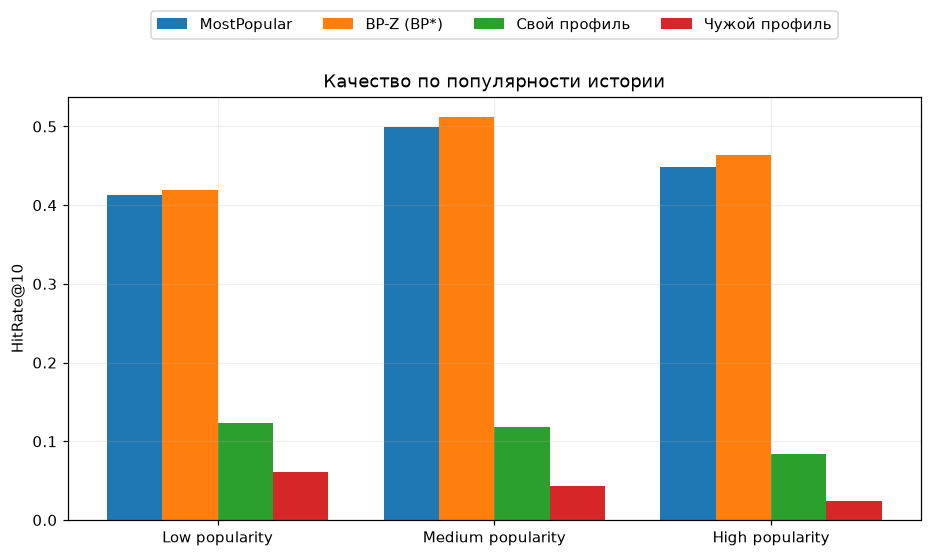

In [17]:
# Средняя популярность определена только для непустых положительных историй.
mean_popularity = np.divide(np.asarray(positive_train @ movie_popularity).ravel(), positive_count,
                            out=np.full(num_users, np.nan), where=positive_count > 0)
eligible = np.flatnonzero(positive_count > 0)
# Основной ключ — средняя популярность, дополнительный — user_id.
sorted_users = eligible[np.lexsort((user_ids[eligible], mean_popularity[eligible]))]
group_names = ['Low popularity', 'Medium popularity', 'High popularity']
groups = dict(zip(group_names, np.array_split(sorted_users, 3)))
test_positive_count = truth_test.getnnz(axis=1)
group_rows = []
user_group = np.full(num_users, 'Undefined', dtype=object)
for name, users in groups.items():
    user_group[users] = name
    group_rows.append({'group': name, 'users': len(users),
                       'mean_positive_train_length': positive_count[users].mean(),
                       'mean_positive_test_in_catalog': test_positive_count[users].mean(),
                       'mean_history_popularity': mean_popularity[users].mean(),
                       'MostPopular_HR': hits_by_model['MostPopular'][users].mean(),
                       'BP_star_HR': hits_by_model[best_bp][users].mean(),
                       'Own_HR': hits_by_model['FeaturesOwn'][users].mean(),
                       'Foreign_HR_mean': hits_foreign[:, users].mean(),
                       'Foreign_HR_std': hits_foreign[:, users].mean(axis=1).std(ddof=1)})
group_results = pd.DataFrame(group_rows)
group_results['Own_minus_Foreign'] = group_results.Own_HR - group_results.Foreign_HR_mean
display(group_results)
print('Исключено из группового анализа из-за пустой положительной train-истории:', num_users-len(eligible))
fig, ax = plt.subplots(figsize=(10, 5))
xx, width = np.arange(3), 0.2
for pos, (col, label) in enumerate([('MostPopular_HR', 'MostPopular'), ('BP_star_HR', best_bp+' (BP*)'),
                                   ('Own_HR', 'Свой профиль'), ('Foreign_HR_mean', 'Чужой профиль')]):
    ax.bar(xx+(pos-1.5)*width, group_results[col], width, label=label)
ax.set(xticks=xx, xticklabels=group_names, ylabel='HitRate@10', title='Качество по популярности истории')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.22), ncol=4)
plt.show()
plt.close(fig)
largest_gain = group_results.loc[group_results.Own_minus_Foreign.idxmax()]
smallest_gain = group_results.loc[group_results.Own_minus_Foreign.idxmin()]

**Разность свой − чужой по группам:** Low popularity: +0.0631; Medium popularity: +0.0750; High popularity: +0.0595. Собственный профиль полезнее чужого во всех трёх группах, но абсолютный прирост различается: наибольший у Medium popularity, наименьший у High popularity. При этом он уступает MostPopular и BP* в каждой из трёх групп. Межгрупповую разницу нельзя целиком объяснить популярностью: длины историй и количество положительных тестовых ответов также различаются. Групповое HitRate не является прямым измерением удовлетворённости пользователя.

## 12. Самостоятельный эксперимент: профиль по 1, 3 и 5 фильмам

Фиксируем одну подгруппу с минимум пятью положительными train-фильмами. В каждом повторе
случайно упорядочиваем положительные фильмы и берём вложенные первые 1/3/5.
Вся прежняя train-история исключается при любом размере профиля. Пользователи и test-ответы одинаковы.
Вариант полного профиля также оцениваем на этой подгруппе. Основной критерий — среднее HitRate
для 5 против 1; промежуточный размер помогает оценить характер изменения.


,profile_size,users,HitRate_mean,HitRate_std,Coverage_mean,Coverage_std
0,1,6021,0.089985,0.002664,0.373058,0.004571
1,3,6021,0.103106,0.004820,0.369202,0.004940
2,5,6021,0.105962,0.003979,0.363715,0.003528


,seed,profile_size,users,HitRate@10,Coverage@10
0,301,1,6021,0.088856,0.371537
1,301,3,6021,0.104800,0.367735
2,301,5,6021,0.103969,0.363661
3,302,1,6021,0.089354,0.379957
4,302,3,6021,0.110115,0.377512
5,302,5,6021,0.110613,0.368007
6,303,1,6021,0.088025,0.368278
7,303,3,6021,0.096994,0.369093
8,303,5,6021,0.108288,0.359044
9,304,1,6021,0.089022,0.375068


Полный профиль на тех же пользователях: {'HitRate@10': 0.10911808669656203, 'Coverage@10': 0.3142313959804454}


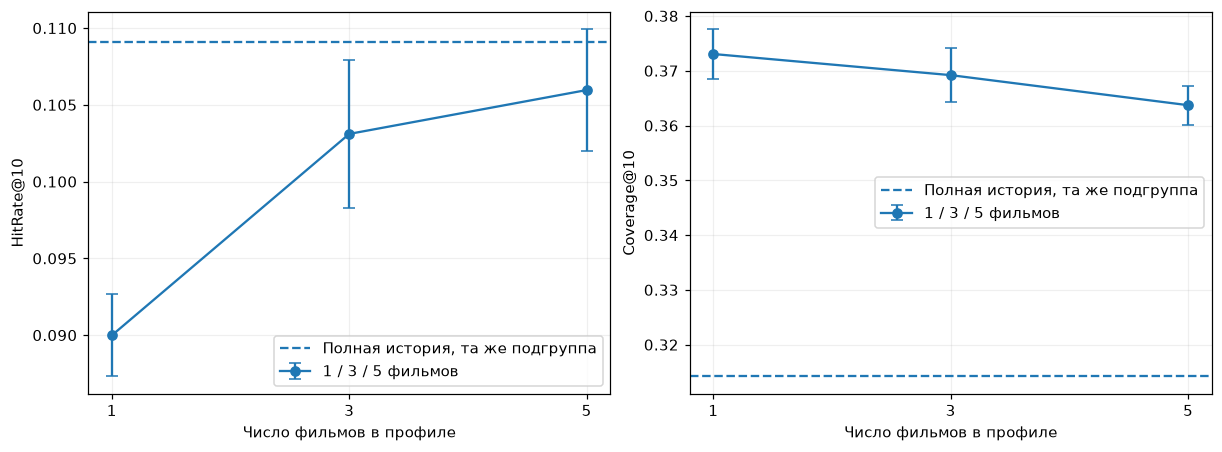

In [18]:
# Во всех вариантах участвуют те же пользователи с минимум 5 положительными фильмами.
size_users = np.flatnonzero(positive_count >= 5)
size_rows = []
for seed in PROFILE_SIZE_SEEDS:
    rng = np.random.default_rng(seed)
    chosen = np.empty((len(size_users), 5), dtype=np.int32)
    for row, user_index in enumerate(size_users):
        positives = positive_train.indices[positive_train.indptr[user_index]:positive_train.indptr[user_index+1]]
        chosen[row] = rng.permutation(positives)[:5]
    # Подмножества вложены: первые 1, 3 и 5 из одного случайного порядка.
    for size in (1, 3, 5):
        limited_profiles = normalize_profiles(genre_vectors[chosen[:, :size]].mean(axis=1))
        profiles_all = np.zeros_like(normalized_profiles)
        profiles_all[size_users] = limited_profiles
        recs = recommend_by_profiles(profiles_all, users=size_users)
        met, _ = metrics(recs, truth_test, users=size_users)
        size_rows.append({'seed': seed, 'profile_size': size, 'users': len(size_users), **met})
size_runs = pd.DataFrame(size_rows)
size_summary = size_runs.groupby('profile_size', sort=True).agg(
    users=('users', 'first'), HitRate_mean=('HitRate@10', 'mean'), HitRate_std=('HitRate@10', 'std'),
    Coverage_mean=('Coverage@10', 'mean'), Coverage_std=('Coverage@10', 'std')).reset_index()
full_subset_metric, _ = metrics(own_recs[size_users], truth_test, users=size_users)
display(size_summary)
display(size_runs)
print('Полный профиль на тех же пользователях:', full_subset_metric)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, metric in zip(axes, ['HitRate', 'Coverage']):
    ax.errorbar(size_summary.profile_size, size_summary[metric+'_mean'],
                yerr=size_summary[metric+'_std'], marker='o', capsize=4, label='1 / 3 / 5 фильмов')
    ax.axhline(full_subset_metric[metric+'@10'], linestyle='--', label='Полная история, та же подгруппа')
    ax.set(xlabel='Число фильмов в профиле', ylabel=metric+'@10', xticks=[1, 3, 5])
    ax.legend()
plt.show()
plt.close(fig)
size_pivot = size_runs.pivot(index='seed', columns='profile_size', values='HitRate@10')
size_delta = size_pivot[5] - size_pivot[1]
size_gain = float(size_delta.mean())

**Проверка гипотезы 2.** Пользователей: **6021**. Средняя разность HitRate
«5 фильмов − 1 фильм»: **+0.0160**; SD парных разностей: **0.0063**.
Положительная разность наблюдалась в **5 из 5** повторов.
Гипотеза поддерживается по среднему направлению эффекта.
Средние HitRate для 1/3/5 фильмов: **0.0900 / 0.1031 / 0.1060**.
Одновременно средний Coverage меняется от **0.3731**
до **0.3637**: рост попаданий не требует роста охвата.

Сравнение парное по seed: меняется размер вложенного профиля, а не участники, test или запреты.
Возможное альтернативное объяснение — усреднение жанров меняет геометрию вектора и число
равных scores; оно не обязательно означает более полное понимание индивидуального вкуса.
Подгруппа с минимум пятью положительными фильмами ограничивает переносимость результата
на пользователей с совсем короткими историями.

## 13. Чем BP-Z отличается от MostPopular и почему BP-N не равен BP-Z

**BP-Z** сортирует по $b(i)=\sum_{u:(u,i)\in O}r_{ui}/|U|$, то есть по сумме train-рейтингов
фильма. **MostPopular** сортирует по $p(i)$ — количеству оценивших пользователей.
Сумма рейтингов равна числу оценок, умноженному на среднюю оценку, поэтому порядки могут различаться.

**При α=1 BP-N не превращается в BP-Z.** В BP-N берётся только случайное мультимножество
неизвестных пар, возможны пропуски и повторы; число нулевых примеров пользователя равно
10q(u). В BP-Z каждая неизвестная пара присутствует ровно один раз. Равный вес отдельного
нуля не делает одинаковыми наборы примеров и суммарные веса. Искусственный ноль — правило обучения,
а не наблюдение о том, что фильм пользователю не понравился.


В эксперименте полностью совпали **0.02%** списков MostPopular и BP-Z. Это сравнение выдач после одинаковой фильтрации train.

## 14. Итоговые выводы и ограничения


1. На нашем случайном разбиении наибольший средний HitRate@10 в общей таблице получил
   **BP-Z**: **0.4651**.
   Это описательное сравнение после фиксации параметров по validation; BP* — **BP-Z**.
2. Собственный жанровый профиль: **0.1088**, чужой: **0.0429 ± 0.0018**.
   Разность **+0.0659**: гипотеза 1 поддерживается по направлению эффекта.
   Относительно MostPopular разность **-0.3447**, относительно BP* — **-0.3563**.
3. Собственный профиль превосходит чужой во всех трёх группах; наибольший абсолютный прирост
   у **Medium popularity** (+0.0750), наименьший —
   у **High popularity** (+0.0595). В каждой группе
   собственный профиль уступает MostPopular и BP*. Группы различаются также характеристиками положительных
   train/test-историй. Поэтому различия HitRate нельзя автоматически приписывать качеству
   персонализации. Конкретные разности своего и чужого профиля приведены в групповом разделе.
4. В дополнительном эксперименте среднее изменение HitRate «5 − 1» равно **+0.0160**:
   гипотеза 2 поддерживается по направлению эффекта.
   Вывод относится к пользователям с минимум пятью положительными train-фильмами.
5. Удаление пользовательской поправки BP-R сохранило **100%** top-10.
   Это подтверждает различие между предсказанием индивидуального уровня оценок и
   персонализацией относительного порядка фильмов.
6. Random достигает Coverage **1.00**, но HitRate
   только **0.0291**. Охват каталога и релевантность —
   разные свойства; высокий охват сам по себе не означает хороших рекомендаций.

**Ограничения выводов:**

- Один датасет MovieLens 1M и одно разбиение: результат может измениться на другой платформе
  или seed; пять подмен не оценивают неопределённость от смены train/test.
- Случайное разбиение не моделирует рекомендацию будущих событий по прошлым. Поэтому метрики
  не являются оценкой качества реального временного развёртывания системы.
- Жанры описывают лишь часть вкусов; равенства scores разрешаются по movie_id.
  Слабый результат жанрового профиля не опровергает пользу персонализации других типов.
- HitRate учитывает только хотя бы одно попадание и зависит от числа положительных ответов;
  он не измеряет позиции, число попаданий или субъективную удовлетворённость.
- Неоценённый фильм не обязательно не нравится пользователю. Искусственные нули BP-N/BP-Z
  могут наказывать потенциально релевантные пары и отражают выбранную обучающую постановку.
- Порог рейтинга ≥4, правило обработки пустых профилей и подгруппа дополнительного
  эксперимента — явные допущения; их изменение может поменять выводы.